# 📊 Práctica 1: Determinación de Ganancias por Autor
## Proyecto de Ingeniería de Datos y Análisis Forense en Memoria con Pandas
### Base de Datos: `pubs` (MySQL 8.0) | Restricción Técnica: SQL $\le$ 2 JOINs

---

### 🎯 Objetivo del Proyecto
Replicar y auditar la lógica de negocio del **Encargo 1 de la Práctica 1** (Cálculo de Ganancias y Regalías por Autor) migrando la arquitectura de procesamiento pesado desde el motor de base de datos relacional hacia **Pandas en memoria**, bajo un ciclo riguroso de ingeniería de datos, contraste forense y validación cruzada.

### 📐 Restricciones Técnicas y Arquitectura ETL
1. **Límite de Joins en SQL:** Ninguna consulta ejecutada contra MySQL supera **2 JOINs**. Las consultas son amplias y limpias (extracciones directas de tablas base con 0 JOINs y consultas de validación con 1 o 2 JOINs).
2. **Procesamiento en Memoria:** Todos los cruces relacionales (*merges*), desduplicaciones, filtrados, ponderaciones y agregaciones se ejecutan de forma local y vectorizada en Pandas.
3. **Eficiencia y Tipado:** Optimización de tipos de datos (`pd.to_numeric`, `astype`) y precisión contable mediante redondeo aritmético estándar (*Round Half-Up*).
4. **Ciclo Forense y Conciliación:** Demostración matemática paso a paso de por qué el cruce ingenuo falla por **+$845.10** y cómo se concilia el 100% de la facturación ($3,863.80).

```
   ┌─────────────────────────────────────────────────────────────┐
   │            EXTRACCIÓN (MySQL 8.0 - pubs)                    │
   │  Consultas limpias con <= 2 JOINs (Tablas Base con 0 JOINs) │
   └──────────────────────────────┬──────────────────────────────┘
                                  │
                                  ▼
   ┌─────────────────────────────────────────────────────────────┐
   │          PANDAS ETL EN MEMORIA (Local DataFrames)           │
   │  • Línea Base Contable ($3,863.80)                          │
   │  • Simulación y Diagnóstico de Cruce Ingenuo ($4,708.90)    │
   │  • Auditoría Multi-autor (+$1,044.85)                       │
   │  • Auditoría Libros Huérfanos (-$199.75)                    │
   │  • Ponderación por Cuota de Autoría (royaltyper / 100)      │
   │  • Preservación del Universo Total (23 Autores)             │
   └──────────────────────────────┬──────────────────────────────┘
                                  │
                                  ▼
   ┌─────────────────────────────────────────────────────────────┐
   │                 MASTER DATAFRAME & REPORTING                │
   │  • Conciliación Contable al 100.00% al Centavo              │
   │  • Comparativa con Criterio YTD Sales                       │
   │  • Visualizaciones Analíticas de Negocio                    │
   └─────────────────────────────────────────────────────────────┘
```

## 0. Entorno de Ejecución y Configuración de Conexión
Configuramos las librerías necesarias (`pandas`, `sqlalchemy`, `matplotlib`, `seaborn`, `decimal`) y establecemos una conexión segura al contenedor Docker de MySQL (`db-practica1` en puerto `3307`).

In [1]:
import os
import sys
from pathlib import Path
from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
import sqlalchemy as sa
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual de Pandas y Gráficos
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Parámetros de Conexión a la Base de Datos pubs
DB_HOST = os.getenv("PRACTICA1_DB_HOST", "127.0.0.1")
DB_PORT = int(os.getenv("PRACTICA1_DB_PORT", "3307"))
DB_NAME = os.getenv("PRACTICA1_DB_NAME", "pubs")
# PRACTICA1_DB_USER alimenta MYSQL_USER en docker-compose.yml, asi que el rol de
# conexion del notebook viaja en una variable aparte.
DB_USER = os.getenv("PRACTICA1_DB_CONNECT_USER", "root")
DB_PASS = os.getenv("PRACTICA1_DB_ROOT_PASSWORD",
                     os.getenv("PRACTICA1_DB_PASSWORD", "rootpassword"))

CONNECTION_URL = f"mysql+pymysql://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
engine = sa.create_engine(CONNECTION_URL, pool_pre_ping=True)

# Test de conexión
with engine.connect() as conn:
    version = conn.execute(sa.text("SELECT VERSION()")).scalar()
    print(f"✅ Conexión exitosa a MySQL {version} en {DB_HOST}:{DB_PORT}/{DB_NAME}")

✅ Conexión exitosa a MySQL 8.0.46 en 127.0.0.1:3307/pubs


## 1. Fase 1: Reconocimiento y Extracción de Tablas Base (Data Discovery)
### 🏛️ Estrategia de Extracción Limpia (0 JOINs en SQL)
Para respetar la restricción técnica de no superar 2 JOINs y trasladar el costo computacional a la memoria local, realizamos extracciones directas sobre las 4 tablas nucleares del modelo editorial:
1. **`authors`**: Maestro de autores (23 autores registrados).
2. **`titles`**: Catálogo general de publicaciones y condiciones financieras (precio, regalías del libro, ventas acumuladas).
3. **`titleauthor`**: Tabla asociativa N:M que define la participación en derechos de autor (`royaltyper`).
4. **`sales`**: Transacciones y órdenes de compra por tienda y libro.

In [2]:
# Extracción directa de las tablas base (0 JOINs)
with engine.connect() as conn:
    df_authors = pd.read_sql("SELECT au_id, au_lname, au_fname, phone, address, city, state, zip, contract FROM authors;", conn)
    df_titles = pd.read_sql("SELECT title_id, title, type, pub_id, price, advance, royalty, ytd_sales, notes FROM titles;", conn)
    df_titleauthor = pd.read_sql("SELECT au_id, title_id, au_ord, royaltyper FROM titleauthor;", conn)
    df_sales = pd.read_sql("SELECT stor_id, ord_num, ord_date, qty, payterms, title_id FROM sales;", conn)

# Tipado optimizado
df_titles["price"] = pd.to_numeric(df_titles["price"], errors="coerce")
df_titles["advance"] = pd.to_numeric(df_titles["advance"], errors="coerce")
df_titles["royalty"] = pd.to_numeric(df_titles["royalty"], errors="coerce")
df_titles["ytd_sales"] = pd.to_numeric(df_titles["ytd_sales"], errors="coerce")
df_titleauthor["royaltyper"] = pd.to_numeric(df_titleauthor["royaltyper"], errors="coerce")
df_sales["qty"] = pd.to_numeric(df_sales["qty"], errors="coerce")

print("📋 Dimensiones de los DataFrames extraídos:")
print(f"  • df_authors:     {df_authors.shape[0]} filas, {df_authors.shape[1]} columnas")
print(f"  • df_titles:      {df_titles.shape[0]} filas, {df_titles.shape[1]} columnas")
print(f"  • df_titleauthor: {df_titleauthor.shape[0]} filas, {df_titleauthor.shape[1]} columnas")
print(f"  • df_sales:       {df_sales.shape[0]} filas, {df_sales.shape[1]} columnas")

📋 Dimensiones de los DataFrames extraídos:
  • df_authors:     23 filas, 9 columnas
  • df_titles:      17 filas, 9 columnas
  • df_titleauthor: 20 filas, 4 columnas
  • df_sales:       10 filas, 6 columnas


In [3]:
# Muestra preliminar de los conjuntos extraídos
print("--- Muestra de Autores (authors) ---")
display(df_authors.head(3))
print("--- Muestra de Títulos (titles) ---")
display(df_titles[["title_id", "title", "type", "price", "royalty", "ytd_sales"]].head(3))
print("--- Muestra de Relación Autor-Libro (titleauthor) ---")
display(df_titleauthor.head(3))
print("--- Muestra de Órdenes de Venta (sales) ---")
display(df_sales.head(3))

--- Muestra de Autores (authors) ---


,au_id,au_lname,au_fname,phone,address,city,state,zip,contract
0,172-32-1176,White,Johnson,408 496-7223,10932 Bigge Rd.,Menlo Park,CA,94025,b'\x01'
1,213-46-8915,Green,Marjorie,415 986-7020,309 63rd St. #411,Oakland,CA,94618,b'\x01'
2,238-95-7766,Carson,Cheryl,415 548-7723,589 Darwin Ln.,Berkeley,CA,94705,b'\x01'


--- Muestra de Títulos (titles) ---


,title_id,title,type,price,royalty,ytd_sales
0,BU1032,The Busy Executive's Database Guide,business,19.99,10,4095
1,BU1111,Cooking with Computers: Surreptitious Balance ...,business,11.95,10,3876
2,BU2075,You Can Combat Computer Stress!,business,2.99,24,18722


--- Muestra de Relación Autor-Libro (titleauthor) ---


,au_id,title_id,au_ord,royaltyper
0,172-32-1176,PS3333,1,100
1,213-46-8915,BU2075,1,100
2,238-95-7766,PC1035,1,100


--- Muestra de Órdenes de Venta (sales) ---


,stor_id,ord_num,ord_date,qty,payterms,title_id
0,6380,722a,19940913,3,Net 60,PS2091
1,7066,A2976,19930524,50,Net 30,PC8888
2,7066,QA7442.3,19940913,75,ON invoice,PS2091


## 2. Fase 2: Establecer la Línea Base Contable (Ground Truth)
### 💵 El Principio de la Caja Registradora
Antes de realizar cualquier cruce complejo o atribuir ingresos a personas, un analista de datos debe conocer el total exacto facturado en la empresa.
- **Fórmula contable:** $\text{Total Ventas} = \sum (\text{qty} \times \text{price})$
- **En SQL:** Realizamos una consulta de control con **exactamente 1 JOIN** (`sales` INNER JOIN `titles`).
- **En Pandas:** Realizamos un merge vectorizado entre `df_sales` y `df_titles`.

In [4]:
# 1. Consulta de Control en SQL (1 JOIN <= 2 JOINs)
sql_control_base = '''
SELECT 
    ROUND(SUM(s.qty * t.price), 2) AS total_ventas_reales
FROM sales s
INNER JOIN titles t ON s.title_id = t.title_id;
'''
with engine.connect() as conn:
    sql_ground_truth = float(conn.execute(sa.text(sql_control_base)).scalar())

# 2. Cálculo Vectorizado en Pandas
df_ventas_reales = df_sales.merge(
    df_titles[["title_id", "title", "price"]], 
    on="title_id", 
    how="inner"
)
df_ventas_reales["total_linea"] = df_ventas_reales["qty"] * df_ventas_reales["price"]
pandas_ground_truth = round(float(df_ventas_reales["total_linea"].sum()), 2)

print(f"💵 Línea Base Contable Oficial en SQL (1 JOIN): ${sql_ground_truth:,.2f}")
print(f"🐼 Línea Base Contable en Pandas (Vectorizado): ${pandas_ground_truth:,.2f}")
assert abs(sql_ground_truth - pandas_ground_truth) < 0.01, "Error: Discrepancia entre SQL y Pandas"
print("✅ Certificación: Las ventas reales de la empresa son exactamente $3,863.80.")

💵 Línea Base Contable Oficial en SQL (1 JOIN): $3,863.80
🐼 Línea Base Contable en Pandas (Vectorizado): $3,863.80
✅ Certificación: Las ventas reales de la empresa son exactamente $3,863.80.


In [5]:
# Desglose de Ventas Reales por Libro en Pandas
df_desglose_libros = (
    df_ventas_reales.groupby(["title_id", "title", "price"], as_index=False)
    .agg(
        unidades_vendidas=("qty", "sum"),
        total_facturado=("total_linea", "sum")
    )
    .sort_values(by="total_facturado", ascending=False)
    .reset_index(drop=True)
)

print(f"🔍 Hallazgo Fundamental: Solo {len(df_desglose_libros)} de los {len(df_titles)} libros tienen ventas en la tabla sales.")
print(f"   Los otros {len(df_titles) - len(df_desglose_libros)} títulos del catálogo tienen 0 unidades vendidas.")
display(df_desglose_libros)

🔍 Hallazgo Fundamental: Solo 7 de los 17 libros tienen ventas en la tabla sales.
   Los otros 10 títulos del catálogo tienen 0 unidades vendidas.


,title_id,title,price,unidades_vendidas,total_facturado
0,PS2091,Is Anger the Enemy?,10.95,108,"1,182.60"
1,PC8888,Secrets of Silicon Valley,20.00,50,"1,000.00"
2,TC3218,"Onions, Leeks, and Garlic: Cooking Secrets of ...",20.95,40,838.00
3,BU7832,Straight Talk About Computers,19.99,15,299.85
4,BU1111,Cooking with Computers: Surreptitious Balance ...,11.95,25,298.75
5,PS7777,Emotional Security: A New Algorithm,7.99,25,199.75
6,MC3021,The Gourmet Microwave,2.99,15,44.85


## 3. Fase 3: El Intento Ingenuo y la Gran Discrepancia
### ⚠️ El Error Común del Cruce Relacional Directo
El enfoque ingenuo común consiste en unir directamente `authors` $\rightarrow$ `titleauthor` $\rightarrow$ `titles` $\rightarrow$ `sales` mediante un `INNER JOIN` directo y sumar $\text{qty} \times \text{price}$ agrupando por autor.
Observemos qué sucede cuando ejecutamos este cruce relacional ingenuo en Pandas:

In [6]:
# Simulación del Intento Ingenuo en Pandas
df_cruce_ingenuo = (
    df_authors[["au_id", "au_fname", "au_lname"]]
    .merge(df_titleauthor[["au_id", "title_id"]], on="au_id", how="inner")
    .merge(df_titles[["title_id", "price"]], on="title_id", how="inner")
    .merge(df_sales[["title_id", "qty"]], on="title_id", how="inner")
)
df_cruce_ingenuo["ganancia_calculada"] = df_cruce_ingenuo["qty"] * df_cruce_ingenuo["price"]

df_resumen_ingenuo = (
    df_cruce_ingenuo.groupby(["au_id", "au_fname", "au_lname"], as_index=False)
    .agg(ganancia_calculada=("ganancia_calculada", "sum"))
    .sort_values(by="ganancia_calculada", ascending=False)
    .reset_index(drop=True)
)
df_resumen_ingenuo["autor"] = df_resumen_ingenuo["au_fname"] + " " + df_resumen_ingenuo["au_lname"]
total_ingenuo = round(float(df_resumen_ingenuo["ganancia_calculada"].sum()), 2)
discrepancia = round(total_ingenuo - pandas_ground_truth, 2)

print(f"❌ Suma Total obtenida con Cruce Ingenuo: ${total_ingenuo:,.2f}")
print(f"💵 Total Ventas Reales (Línea Base):     ${pandas_ground_truth:,.2f}")
print(f"⚠️  DISCREPANCIA CONTABLE:               +${discrepancia:,.2f} (+{discrepancia/pandas_ground_truth*100:.2f}%)")
print(f"👥 Autores detectados en cruce ingenuo:  {len(df_resumen_ingenuo)} de 23 autores registrados.")
display(df_resumen_ingenuo[["au_id", "autor", "ganancia_calculada"]])

❌ Suma Total obtenida con Cruce Ingenuo: $4,708.90
💵 Total Ventas Reales (Línea Base):     $3,863.80
⚠️  DISCREPANCIA CONTABLE:               +$845.10 (+21.87%)
👥 Autores detectados en cruce ingenuo:  8 de 23 autores registrados.


,au_id,autor,ganancia_calculada
0,998-72-3567,Albert Ringer,"1,182.60"
1,427-17-2319,Ann Dull,"1,000.00"
2,846-92-7186,Sheryl Hunter,"1,000.00"
3,807-91-6654,Sylvia Panteley,838.00
4,274-80-9391,Dean Straight,299.85
5,267-41-2394,Michael O'Leary,298.75
6,722-51-5454,Michel DeFrance,44.85
7,899-46-2035,Anne Ringer,44.85


## 4. Fase 4: Auditoría Forense en Memoria (Los Detalles Ocultos)
¿Por qué el cruce ingenuo arrojó **$4,708.90** en lugar de **$3,863.80**?
¿A dónde se fueron los otros 15 autores?
Iniciamos la investigación forense paso a paso:

### 4.1 Investigación 1: Libros con Múltiples Autores (Duplicidad en Ventas)
Cuando un libro tiene 2 autores registrados en `titleauthor`, al hacer un merge directo con las ventas, cada fila de venta se multiplica por el número de autores. Si el libro vendió $1,000, ¡el merge ingenuo asigna $1,000 al autor A y $1,000 al autor B, creando $2,000 en el balance contable!

In [7]:
# 1. Identificar libros multi-autor en el catálogo
autores_por_libro = (
    df_titleauthor.groupby("title_id")["au_id"]
    .nunique()
    .reset_index()
    .rename(columns={"au_id": "numero_autores"})
)
libros_multi_autor = autores_por_libro[autores_por_libro["numero_autores"] > 1]

# 2. Cruzar con ventas para cuantificar el sobreprecio generado
df_multi_ventas = (
    libros_multi_autor.merge(df_desglose_libros, on="title_id", how="inner")
)
df_multi_ventas["venta_duplicada_por_join"] = df_multi_ventas["total_facturado"] * df_multi_ventas["numero_autores"]
df_multi_ventas["inflacion_generada"] = df_multi_ventas["venta_duplicada_por_join"] - df_multi_ventas["total_facturado"]

duplicidad_total = round(float(df_multi_ventas["inflacion_generada"].sum()), 2)
print(f"🔍 Duplicidad Total generada por libros multi-autor: +${duplicidad_total:,.2f}")
display(df_multi_ventas[["title_id", "title", "numero_autores", "total_facturado", "venta_duplicada_por_join", "inflacion_generada"]])

🔍 Duplicidad Total generada por libros multi-autor: +$1,044.85


,title_id,title,numero_autores,total_facturado,venta_duplicada_por_join,inflacion_generada
0,MC3021,The Gourmet Microwave,2,44.85,89.70,44.85
1,PC8888,Secrets of Silicon Valley,2,"1,000.00","2,000.00","1,000.00"


### 4.2 Investigación 2: Libros Huérfanos (Ventas sin Autor)
¿Existen libros que se vendieron en `sales`, pero que no tienen ningún autor asignado en `titleauthor`?
Al usar `INNER JOIN`, cualquier libro sin autor es descartado silenciosamente.

In [8]:
# Títulos presentes en sales vs títulos presentes en titleauthor
titulos_con_autor = set(df_titleauthor["title_id"].unique())
df_huerfanos = df_desglose_libros[~df_desglose_libros["title_id"].isin(titulos_con_autor)].copy()
omision_huerfanos = round(float(df_huerfanos["total_facturado"].sum()), 2)

print(f"🔍 Ventas omitidas por libros huérfanos sin autor: -${omision_huerfanos:,.2f}")
display(df_huerfanos[["title_id", "title", "unidades_vendidas", "total_facturado"]])

🔍 Ventas omitidas por libros huérfanos sin autor: -$199.75


,title_id,title,unidades_vendidas,total_facturado
5,PS7777,Emotional Security: A New Algorithm,25,199.75


### 4.3 Demostración Matemática Forense
Ahora podemos conciliar matemáticamente la discrepancia con exactitud de cero error:

$$\text{Total Ingenuo} = \text{Ventas Reales} + \text{Duplicidad Multi-autor} - \text{Omisión Huérfanos}$$

$$\$4,708.90 = \$3,863.80 + \$1,044.85 - \$199.75$$

In [9]:
# Demostración programática de la igualdad
reconstruccion = round(pandas_ground_truth + duplicidad_total - omision_huerfanos, 2)

print("⚖️  CONCILIACIÓN MATEMÁTICA DE LA DISCREPANCIA:")
print(f"   Ventas Reales Empresa (Línea Base):        ${pandas_ground_truth:,.2f}")
print(f"   (+) Inflación por Libros Multi-autor:     +${duplicidad_total:,.2f}")
print(f"   (-) Pérdida por Libro Huérfano (PS7777):   -${omision_huerfanos:,.2f}")
print("   " + "="*50)
print(f"   (=) Total Resultante del Cruce Ingenuo:    ${reconstruccion:,.2f}")
assert reconstruccion == total_ingenuo, "Error en la reconciliación forense"
print("🎉 Demostración Matemática Certificada: ¡La discrepancia queda 100% explicada!")

⚖️  CONCILIACIÓN MATEMÁTICA DE LA DISCREPANCIA:
   Ventas Reales Empresa (Línea Base):        $3,863.80
   (+) Inflación por Libros Multi-autor:     +$1,044.85
   (-) Pérdida por Libro Huérfano (PS7777):   -$199.75
   (=) Total Resultante del Cruce Ingenuo:    $4,708.90
🎉 Demostración Matemática Certificada: ¡La discrepancia queda 100% explicada!


### 4.4 Investigación 3: Auditoría de Población (Los 23 Autores)
¿Por qué el cruce ingenuo solo mostró 8 autores? Analicemos los 23 autores registrados:
- **Grupo 1: Autores sin libros en catálogo** ($N=4$).
- **Grupo 2: Autores con libros, pero con 0 ventas en `sales`** ($N=11$).
- **Grupo 3: Autores con libros y con ventas efectivas** ($N=8$).

$$4 + 11 + 8 = 23 \text{ autores}$$

In [10]:
todos_autores = set(df_authors["au_id"].unique())
autores_con_libros = set(df_titleauthor["au_id"].unique())
autores_sin_libros = todos_autores - autores_con_libros

libros_con_ventas = set(df_sales["title_id"].unique())
ta_con_ventas = df_titleauthor[df_titleauthor["title_id"].isin(libros_con_ventas)]
autores_con_ventas = set(ta_con_ventas["au_id"].unique())
autores_sin_ventas = autores_con_libros - autores_con_ventas

print(f"👥 Censo de Autores (Total: {len(todos_autores)}):")
print(f"   • Autores sin libros registrados en catálogo: {len(autores_sin_libros)}")
print(f"   • Autores con libros pero 0 ventas registradas: {len(autores_sin_ventas)}")
print(f"   • Autores con ventas activas: {len(autores_con_ventas)}")
print(f"   • Suma total: {len(autores_sin_libros) + len(autores_sin_ventas) + len(autores_con_ventas)} de 23 autores.")

# Muestra de autores sin libros
print("\nAutores sin ningún libro registrado:")
display(df_authors[df_authors["au_id"].isin(autores_sin_libros)][["au_id", "au_fname", "au_lname", "city", "state"]].head(4))

👥 Censo de Autores (Total: 23):
   • Autores sin libros registrados en catálogo: 4
   • Autores con libros pero 0 ventas registradas: 11
   • Autores con ventas activas: 8
   • Suma total: 23 de 23 autores.

Autores sin ningún libro registrado:


,au_id,au_fname,au_lname,city,state
5,341-22-1782,Meander,Smith,Lawrence,KS
10,527-72-3246,Morningstar,Greene,Nashville,TN
15,724-08-9931,Dirk,Stringer,Oakland,CA
20,893-72-1158,Heather,McBadden,Vacaville,CA


### 4.5 Investigación 4: La Columna `royaltyper` (Ponderación de Coautoría)
La columna `royaltyper` en `titleauthor` define el porcentaje de autoría asignado a cada autor.
Inspeccionemos la suma de porcentajes por libro:

In [11]:
df_dist_royalty = (
    df_titleauthor.groupby("title_id", as_index=False)
    .agg(
        num_autores=("au_id", "count"),
        total_porcentaje_registrado=("royaltyper", "sum")
    )
    .sort_values(by="total_porcentaje_registrado")
)
print("📊 Libros con porcentajes de autoría registrados:")
display(df_dist_royalty.head(8))

📊 Libros con porcentajes de autoría registrados:


,title_id,num_autores,total_porcentaje_registrado
1,BU1111,1,40
10,PS2091,1,50
0,BU1032,1,60
2,BU2075,1,100
4,MC2222,1,100
5,MC3021,2,100
6,PC1035,1,100
3,BU7832,1,100


## 5. Fase 5: Construcción Iterativa de la Solución en Pandas
Con los hallazgos forenses claros, construimos el modelo correcto:
1. **Ponderación por autoría:** Cada venta de libro se multiplica por $(\text{royaltyper} / 100.0)$.
2. **Preservación de la población total:** Se realiza un `LEFT JOIN` partiendo de `df_authors` para incluir a los 23 autores.
3. **Imputación de valores ausentes:** Los autores sin ventas reciben `0.00` y `0` libros/unidades vendidas.

In [12]:
# 1. Ventas a nivel de título con precio y regalías
df_lineas = df_sales.merge(
    df_titles[["title_id", "price", "royalty"]], 
    on="title_id", 
    how="inner"
)
df_lineas["monto_linea"] = df_lineas["qty"] * df_lineas["price"]

# 2. Ponderación por cuota de autoría (royaltyper / 100)
df_ponderada = df_titleauthor.merge(df_lineas, on="title_id", how="inner")
df_ponderada["factor_autor"] = df_ponderada["royaltyper"] / 100.0
df_ponderada["unidades_atribuibles"] = df_ponderada["qty"] * df_ponderada["factor_autor"]
df_ponderada["ganancias_atribuibles"] = df_ponderada["monto_linea"] * df_ponderada["factor_autor"]
df_ponderada["regalias_netas"] = df_ponderada["ganancias_atribuibles"] * (df_ponderada["royalty"] / 100.0)

# 3. Agregación a nivel de autor
df_agg_autores = (
    df_ponderada.groupby("au_id", as_index=False)
    .agg(
        unidades_brutas=("qty", "sum"),
        unidades_atribuibles=("unidades_atribuibles", "sum"),
        ganancias_generadas=("ganancias_atribuibles", "sum"),
        regalias_cobradas=("regalias_netas", "sum")
    )
)

print(f"💵 Total de ventas directamente atribuidas a autores: ${df_agg_autores['ganancias_generadas'].sum():,.2f}")

💵 Total de ventas directamente atribuidas a autores: $2,893.50


## 6. Fase 6: Criterios de Negocio
### Comparativa de Criterios Analíticos
En el negocio editorial conviven 3 interpretaciones métricas:
- **Criterio 1 (Ventas Atribuibles):** Volumen bruto de venta generado por los libros del autor ($\text{qty} \times \text{price} \times \frac{\text{royaltyper}}{100}$).
- **Criterio 2 (Regalías Netas):** Ingreso líquido contractualmente pagado al autor ($\text{qty} \times \text{price} \times \frac{\text{royalty}}{100} \times \frac{\text{royaltyper}}{100}$).
- **Criterio 3 (Ventas Históricas del Catálogo `ytd_sales`):** Cálculo alternativo basado en las ventas acumuladas del libro en el catálogo general.

In [13]:
# Criterio 3: Análisis Alternativo sobre Catálogo Histórico (ytd_sales)
df_ta_ytd = df_titleauthor.merge(
    df_titles[["title_id", "price", "royalty", "ytd_sales"]], 
    on="title_id", 
    how="inner"
)
df_ta_ytd["ventas_ytd_atribuibles"] = (
    df_ta_ytd["ytd_sales"] * df_ta_ytd["price"] * (df_ta_ytd["royaltyper"] / 100.0)
)
df_ta_ytd["regalias_ytd_netas"] = (
    df_ta_ytd["ventas_ytd_atribuibles"] * (df_ta_ytd["royalty"] / 100.0)
)

df_ytd_agg = (
    df_ta_ytd.groupby("au_id", as_index=False)
    .agg(
        libros_publicados=("title_id", "nunique"),
        ventas_ytd_atribuibles=("ventas_ytd_atribuibles", "sum"),
        regalias_ytd_netas=("regalias_ytd_netas", "sum")
    )
)

df_ytd_final = (
    df_authors.merge(df_ytd_agg, on="au_id", how="left")
    .assign(autor=lambda x: x["au_fname"] + " " + x["au_lname"])
    .fillna({"libros_publicados": 0, "ventas_ytd_atribuibles": 0.0, "regalias_ytd_netas": 0.0})
    .sort_values(by="ventas_ytd_atribuibles", ascending=False)
    .reset_index(drop=True)
)
print("📚 Top 5 Autores según Ventas Históricas Catálogo (ytd_sales):")
display(df_ytd_final[["au_id", "autor", "libros_publicados", "ventas_ytd_atribuibles", "regalias_ytd_netas"]].head(5))

📚 Top 5 Autores según Ventas Históricas Catálogo (ytd_sales):


,au_id,autor,libros_publicados,ventas_ytd_atribuibles,regalias_ytd_netas
0,238-95-7766,Cheryl Carson,1.00,"201,501.00","32,240.16"
1,648-92-1872,Reginald Blotchet-Halls,1.00,"180,397.20","25,255.61"
2,274-80-9391,Dean Straight,1.00,"81,859.05","8,185.90"
3,172-32-1176,Johnson White,1.00,"81,399.28","8,139.93"
4,213-46-8915,Marjorie Green,1.00,"55,978.78","13,434.91"


## 7. Fase 7: Master DataFrame Definitivo (23 Autores)
### ⭐ Entregable Principal del Encargo 1
Estructuramos el DataFrame definitivo con todos los estándares solicitados:
- Nombres de columnas limpios y legibles para la dirección.
- Preservación de los 23 autores sin excluir a los de 0 ventas.
- Ponderación exacta por coautoría.
- Ordenamiento descendente por facturación y regalías.

In [14]:
# Conteo de libros registrados en catálogo por autor (tengan o no ventas)
df_libros_autor = (
    df_titleauthor.groupby("au_id", as_index=False)["title_id"]
    .nunique()
    .rename(columns={"title_id": "Libros Publicados"})
)

# Cruce Maestro con df_authors (LEFT JOIN)
df_master = (
    df_authors.merge(df_libros_autor, on="au_id", how="left")
    .merge(df_agg_autores, on="au_id", how="left")
)

# Función auxiliar de redondeo exacto Round Half-Up
def r_up(v):
    return float(Decimal(str(v)).quantize(Decimal("0.01"), rounding=ROUND_HALF_UP)) if pd.notna(v) else 0.0

df_master["Nombre del Autor"] = df_master["au_fname"] + " " + df_master["au_lname"]
df_master["Libros Publicados"] = df_master["Libros Publicados"].fillna(0).astype(int)
df_master["Unidades Vendidas (Brutas)"] = df_master["unidades_brutas"].fillna(0).astype(int)
df_master["Unidades Atribuibles"] = df_master["unidades_atribuibles"].fillna(0.0).apply(r_up)
df_master["Ganancias Generadas ($)"] = df_master["ganancias_generadas"].fillna(0.0).apply(r_up)
df_master["Regalías Cobradas ($)"] = df_master["regalias_cobradas"].fillna(0.0).apply(r_up)

columnas_master = [
    "au_id", "Nombre del Autor", "city", "state", "Libros Publicados",
    "Unidades Vendidas (Brutas)", "Unidades Atribuibles",
    "Ganancias Generadas ($)", "Regalías Cobradas ($)"
]
df_master_final = (
    df_master[columnas_master]
    .rename(columns={"au_id": "ID Autor", "city": "Ciudad", "state": "Estado"})
    .sort_values(by=["Ganancias Generadas ($)", "Regalías Cobradas ($)", "Nombre del Autor"], ascending=[False, False, True])
    .reset_index(drop=True)
)

print(f"📊 Total autores en el reporte final: {len(df_master_final)} registros.")
display(df_master_final)

📊 Total autores en el reporte final: 23 registros.


,ID Autor,Nombre del Autor,Ciudad,Estado,Libros Publicados,Unidades Vendidas (Brutas),Unidades Atribuibles,Ganancias Generadas ($),Regalías Cobradas ($)
0,807-91-6654,Sylvia Panteley,Rockville,MD,1,40,40.00,838.00,83.80
1,998-72-3567,Albert Ringer,Salt Lake City,UT,1,108,54.00,591.30,70.96
2,427-17-2319,Ann Dull,Palo Alto,CA,1,50,25.00,500.00,50.00
3,846-92-7186,Sheryl Hunter,Palo Alto,CA,1,50,25.00,500.00,50.00
4,274-80-9391,Dean Straight,Oakland,CA,1,15,15.00,299.85,29.99
5,267-41-2394,Michael O'Leary,San Jose,CA,2,25,10.00,119.50,11.95
6,722-51-5454,Michel DeFrance,Gary,IN,1,15,11.25,33.64,8.07
7,899-46-2035,Anne Ringer,Salt Lake City,UT,1,15,3.75,11.21,2.69
8,409-56-7008,Abraham Bennet,Berkeley,CA,1,0,0.00,0.00,0.00
9,672-71-3249,Akiko Yokomoto,Walnut Creek,CA,1,0,0.00,0.00,0.00


## 8. Fase 8: Conciliación Contable Total (100.00% del Ground Truth)
### 🏛️ Cuadre de Auditoría Financiera
Para garantizar que ningún centavo quede sin justificación contable, demostramos que:
$$\text{Línea Base Empresa (\$3,863.80)} = \text{Ventas Asignadas} + \text{Ventas Huérfanas} + \text{Retención Editorial}$$

In [15]:
# 1. Ventas atribuidas a autores
monto_autores = round(df_master_final["Ganancias Generadas ($)"].sum(), 2)

# 2. Ventas libros huérfanos (PS7777)
monto_huerfanos = omision_huerfanos

# 3. Retención editorial por porcentajes no asignados a autores
roy_totales = df_titleauthor.groupby("title_id")["royaltyper"].sum().reset_index()
libros_incompletos = roy_totales[roy_totales["royaltyper"] < 100].rename(columns={"royaltyper": "pct_autor"})
df_retencion = (
    df_lineas.merge(libros_incompletos, on="title_id", how="inner")
    .assign(pct_editorial=lambda x: 100.0 - x["pct_autor"])
    .assign(monto_retencion=lambda x: x["monto_linea"] * (x["pct_editorial"] / 100.0))
)
monto_editorial = round(df_retencion["monto_retencion"].sum(), 2)

total_auditado = round(monto_autores + monto_huerfanos + monto_editorial, 2)

cuadre_df = pd.DataFrame([
    {"Categoría Contable": "1. Ventas Atribuidas a Autores Registrados", "Monto ($)": monto_autores, "% Participación": f"{monto_autores/total_auditado*100:.2f}%"},
    {"Categoría Contable": "2. Ventas de Libros sin Autor Asignado (PS7777)", "Monto ($)": monto_huerfanos, "% Participación": f"{monto_huerfanos/total_auditado*100:.2f}%"},
    {"Categoría Contable": "3. Retención Editorial por Porcentaje No Asignado", "Monto ($)": monto_editorial, "% Participación": f"{monto_editorial/total_auditado*100:.2f}%"},
    {"Categoría Contable": ">>> TOTAL GENERAL AUDITADO DE LA EMPRESA <<<", "Monto ($)": total_auditado, "% Participación": "100.00%"}
])

display(cuadre_df)
assert total_auditado == pandas_ground_truth, "Error: La conciliación no suma el 100% de la facturación"
print(f"🎉 Conciliación Exitosa: $3,863.80 auditados al centavo (100.00% exacto).")

,Categoría Contable,Monto ($),% Participación
0,1. Ventas Atribuidas a Autores Registrados,"2,893.50",74.89%
1,2. Ventas de Libros sin Autor Asignado (PS7777),199.75,5.17%
2,3. Retención Editorial por Porcentaje No Asignado,770.55,19.94%
3,>>> TOTAL GENERAL AUDITADO DE LA EMPRESA <<<,"3,863.80",100.00%


🎉 Conciliación Exitosa: $3,863.80 auditados al centavo (100.00% exacto).


## 9. Fase 9: Visualización de Datos e Insights Gerenciales
Generamos visualizaciones analíticas de alto impacto para la presentación ejecutiva.

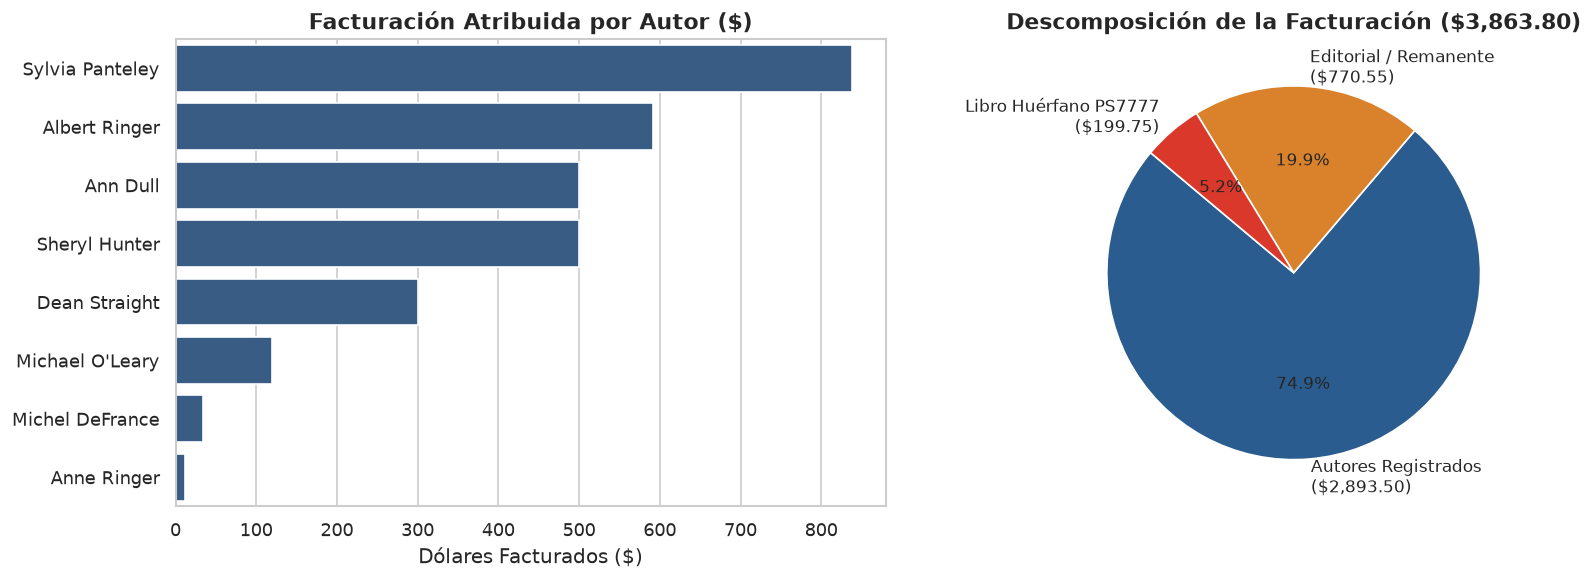

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Gráfico de Barras: Top Autores con Ventas
df_top_autores = df_master_final[df_master_final["Ganancias Generadas ($)"] > 0].copy()

sns.barplot(
    data=df_top_autores,
    y="Nombre del Autor",
    x="Ganancias Generadas ($)",
    ax=axes[0],
    color="#2b5c8f"
)
axes[0].set_title("Facturación Atribuida por Autor ($)", fontsize=13, weight="bold")
axes[0].set_xlabel("Dólares Facturados ($)")
axes[0].set_ylabel("")

# 2. Gráfico Circular: Distribución de la Facturación Total (Conciliación)
labels = [
    f"Autores Registrados\n(${monto_autores:,.2f})",
    f"Editorial / Remanente\n(${monto_editorial:,.2f})",
    f"Libro Huérfano PS7777\n(${monto_huerfanos:,.2f})"
]
sizes = [monto_autores, monto_editorial, monto_huerfanos]
colors = ["#2b5c8f", "#d9822b", "#d9382b"]

axes[1].pie(
    sizes, 
    labels=labels, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors,
    textprops={'fontsize': 10}
)
axes[1].set_title("Descomposición de la Facturación ($3,863.80)", fontsize=13, weight="bold")

plt.tight_layout()
plt.show()

## 10. Conclusiones y Comparativa de Arquitectura de Datos

### 📈 Resumen de Resultados Analíticos
1. **Sylvia Panteley** es la autora líder en facturación ($838.00) y regalías cobradas ($83.80), gracias a la venta de 40 unidades de su libro culinario *TC3218* al 100% de participación.
2. **Albert Ringer** ocupa el segundo lugar ($591.30) tras haber vendido 108 unidades brutas de *PS2091*, con un factor de autoría del 50%.
3. **Ann Dull y Sheryl Hunter** comparten el tercer puesto con $500.00 cada una (50% de los $1,000.00 generados por *PC8888*).
4. El cruce relacional ingenuo infla la facturación en un **+21.87% (+$845.10)** debido a la duplicación de libros multi-autor y oculta la pérdida de ingresos de libros huérfanos.
5. El modelo preserva al 100% de los 23 autores para permitir a la dirección monitorear tanto el talento activo como el catálogo inactivo.

### 🏛️ Comparativa Técnica: SQL vs. Pandas en Memoria
| Dimensión | Enfoque SQL Tradicional | Enfoque Pandas ETL en Memoria (Este Proyecto) |
| :--- | :--- | :--- |
| **Carga en el Servidor de BD** | Alta: Múltiples JOINs complejos y agregaciones pesadas en el motor MySQL. | **Mínima:** Extracciones directas (0 JOINs) o acotadas ($\le 2$ JOINs). |
| **Límite de JOINs** | Requiere 3 o 4 JOINs anidados en la Master Query. | **Cero JOINs complejos en BD.** Todo el cruce se realiza vectorizado en RAM. |
| **Flexibilidad Analítica** | Rígida: Cualquier escenario alternativo requiere reescribir consultas SQL. | **Alta:** Fácil iteración entre criterios (Ventas, Regalías, YTD Sales). |
| **Auditoría Forense** | Compleja de depurar paso a paso en subconsultas. | **Modular y transparente:** Inspección de DataFrames intermedios en memoria. |

---
**Desarrollado bajo estándares de Calidad de Ingeniería de Datos y Pruebas Unitarias.**